# Metrical BDI: evaluation and calibration

This notebook evaluates and calibrates the metrical Bootstrap Distance Imposters (BDI) procedure on texts of known authorship.

It uses the metrical corpus created by `1. clusterization metric.ipynb` and keeps the two texts to be attributed completely outside calibration:

- `X_operibus`
- `X2_cilr`

The metrical representation, BDI distance and bootstrap settings are unchanged from the application notebook:

- metrical vectors produced by `elegy.vectorise_babs`;
- `minmax` / Ružička distance;
- 1000 bootstrap iterations;
- `rnd_prop = 0.35`.

Calibration consists of 800 known-authorship verification problems:

- 400 same-author comparisons;
- 400 different-author comparisons.

For every problem, the query segment is removed from the comparison corpus before BDI is fitted. A logistic regression then converts BDI match strength into a corpus-specific probability of same authorship.

The reported classification performance refers to the **calibration sample** itself, as in the lexical-analysis workflow.


In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

import joblib

from bdi import BDIVerifier

logging.basicConfig(level="WARNING")


## Paths and input corpus

In [4]:
def find_metrical_root():
    current = Path.cwd().resolve()

    for folder in [current, *current.parents]:
        if (folder / "output.csv").is_file():
            return folder

    raise FileNotFoundError(
        "Could not find the Metrical analysis root containing output.csv."
    )


BASE_DIR = find_metrical_root()
CORPUS_PATH = BASE_DIR / "output.csv"

print(f"Metrical analysis root: {BASE_DIR}")
print(f"Input corpus:           {CORPUS_PATH}")


Metrical analysis root: /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Metrical analysis
Input corpus:           /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Metrical analysis/output.csv


In [5]:
raw_df = pd.read_csv(CORPUS_PATH, encoding="utf-8")

print(f"Loaded {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
print(f"Authors/codes: {sorted(raw_df['Author'].astype(str).unique())}")
print()

display(
    raw_df.groupby(["Author", "Work"])
    .size()
    .rename("n_segments")
    .reset_index()
)


Loaded 442 rows, 46 columns
Authors/codes: ['AE', 'ASt', 'BB', 'BBi', 'BI', 'BM', 'BS', 'EM', 'H', 'HA', 'HM', 'HW', 'IS', 'M', 'NLC', 'PDE', 'PR', 'QS', 'RDV', 'RL', 'RT', 'SAC', 'SR', 'U1', 'U2', 'U3', 'U4', 'X', 'X2']



,Author,Work,n_segments
0,AE,bhc,3
1,ASt,troilus,29
2,BB,adelae,6
3,BBi,speculum,9
4,BI,reynardus,8
5,BM,regum,4
6,BS,mathematicus,4
7,EM,mahumeti,5
8,H,carmina,2
9,H,mysterio,3


## Holdouts

`X_operibus` and `X2_cilr` are retained in `output.csv` so that the application notebooks can use them later, but neither contributes to scaling, BDI calibration or logistic calibration.


In [7]:
HOLDOUT_AUTHORS = {"X", "X2"}

holdout_mask = raw_df["Author"].astype(str).isin(HOLDOUT_AUTHORS)
known_mask = ~holdout_mask

known_df = raw_df.loc[known_mask].copy()
holdout_df = raw_df.loc[holdout_mask].copy()

print(f"Known-author segments: {len(known_df)}")
print(f"Holdout segments:      {len(holdout_df)}")

print("\nHoldouts:")
display(
    holdout_df.groupby(["Author", "Work"])
    .size()
    .rename("n_segments")
    .reset_index()
)

expected = {("X", "operibus"), ("X2", "cilr")}
found = set(
    holdout_df[["Author", "Work"]]
    .astype(str)
    .itertuples(index=False, name=None)
)

missing = expected - found
if missing:
    print(f"WARNING: expected holdout pairs not found: {sorted(missing)}")


Known-author segments: 435
Holdout segments:      7

Holdouts:


,Author,Work,n_segments
0,X,operibus,1
1,X2,cilr,6


## Labels and scaling

In [9]:
# Encode known authors only.
label_encoder = LabelEncoder()
known_df["author_label"] = label_encoder.fit_transform(
    known_df["Author"].astype(str)
)

mapping = (
    known_df[["Author", "author_label"]]
    .drop_duplicates()
    .sort_values("author_label")
)

print("Known-author label mapping:")
print(mapping.to_string(index=False))

joblib.dump(
    label_encoder,
    BASE_DIR / "metrical_label_encoder.pkl",
)


Known-author label mapping:
Author  author_label
    AE             0
   ASt             1
    BB             2
   BBi             3
    BI             4
    BM             5
    BS             6
    EM             7
     H             8
    HA             9
    HM            10
    HW            11
    IS            12
     M            13
   NLC            14
   PDE            15
    PR            16
    QS            17
   RDV            18
    RL            19
    RT            20
   SAC            21
    SR            22
    U1            23
    U2            24
    U3            25
    U4            26


['/Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Metrical analysis/metrical_label_encoder.pkl']

In [10]:
# Preserve the same numeric metrical feature set used by the original
# metrics_bdi notebook. The holdouts are excluded from scaler fitting.
numeric_cols = raw_df.select_dtypes(include=["number"]).columns.tolist()

if not numeric_cols:
    raise ValueError("No numeric metrical features found in output.csv.")

scaler = StandardScaler(with_mean=False)
scaler.fit(known_df[numeric_cols])

known_scaled = pd.DataFrame(
    scaler.transform(known_df[numeric_cols]),
    columns=numeric_cols,
    index=known_df.index,
)

known_scaled["author_label"] = known_df["author_label"].values

joblib.dump(
    scaler,
    BASE_DIR / "metrical_scaler.pkl",
)

print(f"Numeric metrical features: {len(numeric_cols)}")
print(f"Scaler fitted on {len(known_df)} known-author segments only.")
print("Holdout segments used for scaler fitting: 0")


Numeric metrical features: 43
Scaler fitted on 435 known-author segments only.
Holdout segments used for scaler fitting: 0


## BDI calibration

The query segment is held out from the comparison corpus in every calibration problem.

Authors represented by only one segment cannot provide a same-author query because removing that segment would leave no known sample for the candidate. Such authors remain available as impostors and as candidates in different-author problems.


In [12]:
N_SAME = 400
N_DIFFERENT = 400

N_BOOTSTRAP = 1000
RND_PROP = 0.35

CALIBRATION_SEED = 42
master_rng = np.random.default_rng(CALIBRATION_SEED)

author_counts = known_df["author_label"].value_counts()

same_valid_labels = set(
    author_counts[author_counts >= 2].index
)

same_valid_indices = known_df.index[
    known_df["author_label"].isin(same_valid_labels)
].to_numpy(copy=True)

all_known_indices = known_df.index.to_numpy(copy=True)
all_known_labels = sorted(known_df["author_label"].unique())

print(f"Known authors: {len(all_known_labels)}")
print(f"Known segments: {len(all_known_indices)}")
print(
    "Authors eligible to provide same-author Q: "
    f"{len(same_valid_labels)}"
)

if len(same_valid_indices) == 0:
    raise ValueError(
        "No author has at least two known segments; "
        "same-author calibration cannot be performed."
    )


Known authors: 27
Known segments: 435
Authors eligible to provide same-author Q: 27


In [13]:
def run_metric_bdi_case(
    q_index: int,
    candidate_label: int,
    seed: int,
) -> float:
    """
    Run one leave-one-segment-out metrical BDI verification problem.
    """
    pool_indices = known_df.index[known_df.index != q_index]

    pool_X = known_scaled.loc[
        pool_indices,
        numeric_cols,
    ].to_numpy()

    pool_y = known_df.loc[
        pool_indices,
        "author_label",
    ].to_numpy()

    q_X = known_scaled.loc[
        [q_index],
        numeric_cols,
    ].to_numpy()

    if candidate_label not in set(pool_y):
        raise ValueError(
            f"Candidate label {candidate_label} has no comparison segment "
            f"after holding out Q={q_index}."
        )

    verifier = BDIVerifier(
        metric="minmax",
        nb_bootstrap_iter=N_BOOTSTRAP,
        rnd_prop=RND_PROP,
        random_state=np.random.default_rng(seed),
    )

    verifier.fit(pool_X, pool_y)
    score = verifier.predict_proba(
        q_X,
        [candidate_label],
    )

    return float(np.asarray(score).reshape(-1)[0])


In [14]:
calibration_rows = []

# ---------------------------------------------------------
# 400 SAME-AUTHOR problems
# ---------------------------------------------------------
same_q_indices = master_rng.choice(
    same_valid_indices,
    size=N_SAME,
    replace=True,
)

for q_index in tqdm(
    same_q_indices,
    desc="Same-author calibration",
):
    q_label = int(known_df.loc[q_index, "author_label"])
    q_author = str(known_df.loc[q_index, "Author"])
    q_work = str(known_df.loc[q_index, "Work"])

    seed = int(master_rng.integers(0, 2**32 - 1))

    score = run_metric_bdi_case(
        q_index=int(q_index),
        candidate_label=q_label,
        seed=seed,
    )

    calibration_rows.append(
        {
            "type": "same",
            "q_index": int(q_index),
            "q_author": q_author,
            "q_work": q_work,
            "candidate": q_author,
            "match_strength": score,
        }
    )


# ---------------------------------------------------------
# 400 DIFFERENT-AUTHOR problems
# ---------------------------------------------------------
different_q_indices = master_rng.choice(
    all_known_indices,
    size=N_DIFFERENT,
    replace=True,
)

for q_index in tqdm(
    different_q_indices,
    desc="Different-author calibration",
):
    q_label = int(known_df.loc[q_index, "author_label"])
    q_author = str(known_df.loc[q_index, "Author"])
    q_work = str(known_df.loc[q_index, "Work"])

    wrong_candidates = [
        label
        for label in all_known_labels
        if int(label) != q_label
    ]

    candidate_label = int(
        master_rng.choice(wrong_candidates)
    )
    candidate_author = str(
        label_encoder.inverse_transform([candidate_label])[0]
    )

    seed = int(master_rng.integers(0, 2**32 - 1))

    score = run_metric_bdi_case(
        q_index=int(q_index),
        candidate_label=candidate_label,
        seed=seed,
    )

    calibration_rows.append(
        {
            "type": "different",
            "q_index": int(q_index),
            "q_author": q_author,
            "q_work": q_work,
            "candidate": candidate_author,
            "match_strength": score,
        }
    )


calibration_df = pd.DataFrame(calibration_rows)

calibration_df.to_csv(
    BASE_DIR / "metrical_bdi_calibration.csv",
    index=False,
)

print(f"Calibration problems completed: {len(calibration_df)}")


Same-author calibration:   0%|          | 0/400 [00:00<?, ?it/s]

Different-author calibration:   0%|          | 0/400 [00:00<?, ?it/s]

Calibration problems completed: 800


## Calibration distributions

In [16]:
summary_stats = (
    calibration_df.groupby("type")["match_strength"]
    .agg(["count", "mean", "std", "median", "min", "max"])
)

display(summary_stats)

same_mean = calibration_df.loc[
    calibration_df["type"] == "same",
    "match_strength",
].mean()

different_mean = calibration_df.loc[
    calibration_df["type"] == "different",
    "match_strength",
].mean()

print(
    f"Mean BDI match strength, same author:      "
    f"{same_mean:.4f}"
)
print(
    f"Mean BDI match strength, different author: "
    f"{different_mean:.4f}"
)


,count,mean,std,median,min,max
type,,,,,,
different,400,0.096380,0.163819,0.028,0.000,0.886
same,400,0.920083,0.176134,0.993,0.007,1.000


Mean BDI match strength, same author:      0.9201
Mean BDI match strength, different author: 0.0964


## Logistic calibration and evaluation

In [18]:
y = (
    calibration_df["type"] == "same"
).astype(int).to_numpy()

X_cal = calibration_df[
    ["match_strength"]
].to_numpy(dtype=float)

bdi_calibration_model = LogisticRegression()
bdi_calibration_model.fit(X_cal, y)

y_pred = bdi_calibration_model.predict(X_cal)
y_prob = bdi_calibration_model.predict_proba(X_cal)[:, 1]

calibration_df["predicted_same"] = y_pred
calibration_df["calibrated_probability"] = y_prob

coef = float(
    bdi_calibration_model.coef_[0][0]
)
intercept = float(
    bdi_calibration_model.intercept_[0]
)

threshold_match = (
    -intercept / coef
    if coef != 0
    else np.nan
)

print(f"Coefficient: {coef:.6f}")
print(f"Intercept:   {intercept:.6f}")
print(
    "BDI match strength corresponding to P(same author)=0.5: "
    f"{threshold_match:.4f}"
)

print(
    "\n=== Classification report: calibration sample ==="
)
print(
    classification_report(
        y,
        y_pred,
        target_names=[
            "different author",
            "same author",
        ],
        digits=4,
    )
)

print("Confusion matrix:")
print(confusion_matrix(y, y_pred))

joblib.dump(
    bdi_calibration_model,
    BASE_DIR / "metrical_bdi_calibration_model.pkl",
)

calibration_df.to_csv(
    BASE_DIR / "metrical_bdi_calibration_with_probabilities.csv",
    index=False,
)


Coefficient: 7.079981
Intercept:   -3.545480
BDI match strength corresponding to P(same author)=0.5: 0.5008

=== Classification report: calibration sample ===
                  precision    recall  f1-score   support

different author     0.9459    0.9625    0.9542       400
     same author     0.9618    0.9450    0.9533       400

        accuracy                         0.9537       800
       macro avg     0.9539    0.9537    0.9537       800
    weighted avg     0.9539    0.9537    0.9537       800

Confusion matrix:
[[385  15]
 [ 22 378]]


## Calibration plot

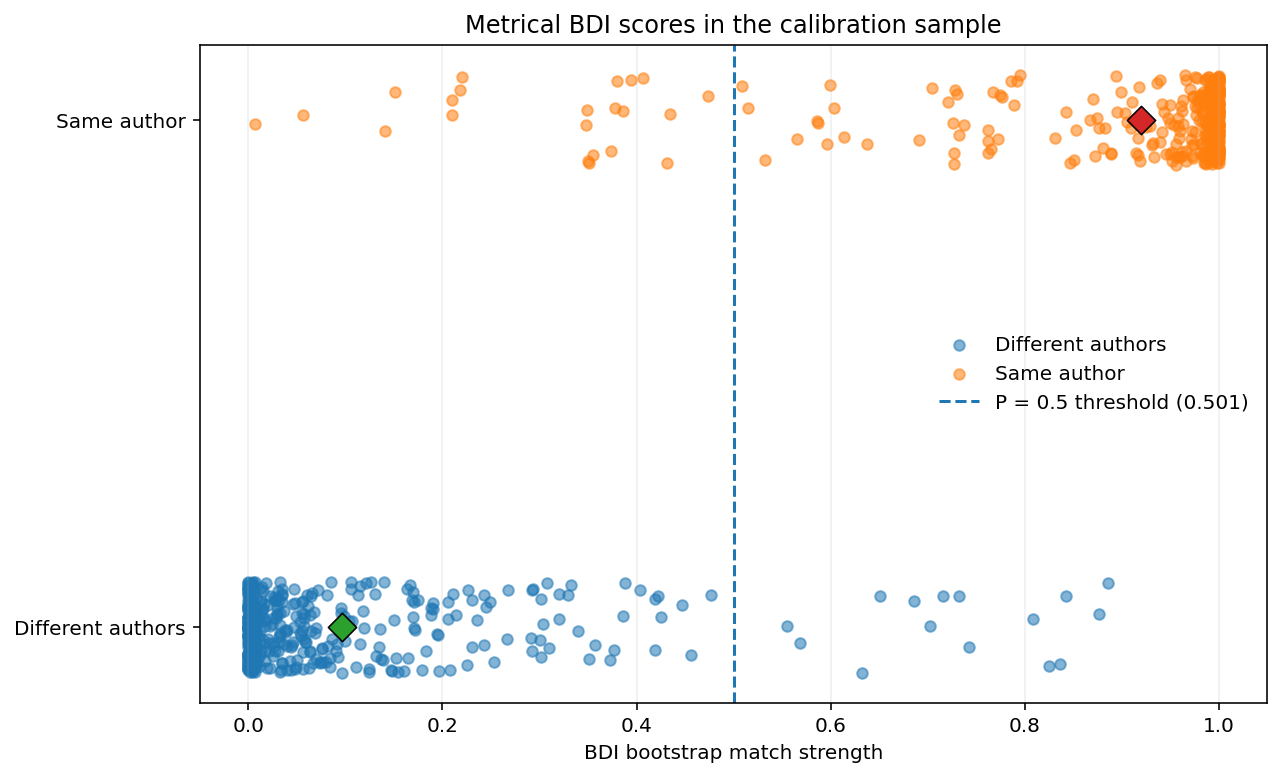

In [20]:
plot_rng = np.random.default_rng(42)

same_scores = calibration_df.loc[
    calibration_df["type"] == "same",
    "match_strength",
].to_numpy()

different_scores = calibration_df.loc[
    calibration_df["type"] == "different",
    "match_strength",
].to_numpy()

y_same = 1 + plot_rng.uniform(
    -0.09,
    0.09,
    size=len(same_scores),
)

y_different = 0 + plot_rng.uniform(
    -0.09,
    0.09,
    size=len(different_scores),
)

fig, ax = plt.subplots(
    figsize=(9, 5.5),
    dpi=144,
)

ax.scatter(
    different_scores,
    y_different,
    s=28,
    alpha=0.55,
    label="Different authors",
)

ax.scatter(
    same_scores,
    y_same,
    s=28,
    alpha=0.55,
    label="Same author",
)

if np.isfinite(threshold_match):
    ax.axvline(
        threshold_match,
        linestyle="--",
        linewidth=1.5,
        label=(
            f"P = 0.5 threshold "
            f"({threshold_match:.3f})"
        ),
    )

ax.scatter(
    different_scores.mean(),
    0,
    s=100,
    marker="D",
    edgecolor="black",
    linewidth=0.8,
    zorder=5,
)

ax.scatter(
    same_scores.mean(),
    1,
    s=100,
    marker="D",
    edgecolor="black",
    linewidth=0.8,
    zorder=5,
)

ax.set_yticks([0, 1])
ax.set_yticklabels(
    ["Different authors", "Same author"]
)

ax.set_xlabel("BDI bootstrap match strength")
ax.set_ylabel("")
ax.set_title(
    "Metrical BDI scores in the calibration sample"
)

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

fig.savefig(
    BASE_DIR / "metrical_bdi_calibration.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    BASE_DIR / "metrical_bdi_calibration.pdf",
    bbox_inches="tight",
)

plt.show()


## Files produced

The notebook writes the following reusable files in the general `Metrical analysis` directory:

- `metrical_scaler.pkl`: scaler fitted only on known-author metrical segments;
- `metrical_label_encoder.pkl`: mapping of known-author codes to integer labels;
- `metrical_bdi_calibration_model.pkl`: logistic calibration model;
- `metrical_bdi_calibration.csv`: raw 800 calibration comparisons;
- `metrical_bdi_calibration_with_probabilities.csv`: calibration comparisons with calibrated probabilities;
- `metrical_bdi_calibration.png` / `.pdf`: calibration plot.

The application notebooks for `X_operibus` and `X2_cilr` should load these files rather than recalibrating the method.
